In [2]:
%load_ext autoreload
%autoreload 2
import os, sys
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.optimize import brentq
from IPython.display import Image, display

In [6]:
# Output directories for results and plots
outputs_dir = os.path.join(os.getcwd(), 'outputs')
os.makedirs(outputs_dir, exist_ok=True)
OUT = Path(outputs_dir) / 'figure3_safer_correlated_proxy_outputs'
OUT.mkdir(parents=True, exist_ok=True)

plots_dir = os.path.join(os.getcwd(), 'plots')
os.makedirs(plots_dir, exist_ok=True)

Starting computation...
Completed 10 / 61 k1 grid values
Completed 20 / 61 k1 grid values
Completed 30 / 61 k1 grid values
Completed 40 / 61 k1 grid values
Completed 50 / 61 k1 grid values
Completed 60 / 61 k1 grid values
Completed 61 / 61 k1 grid values


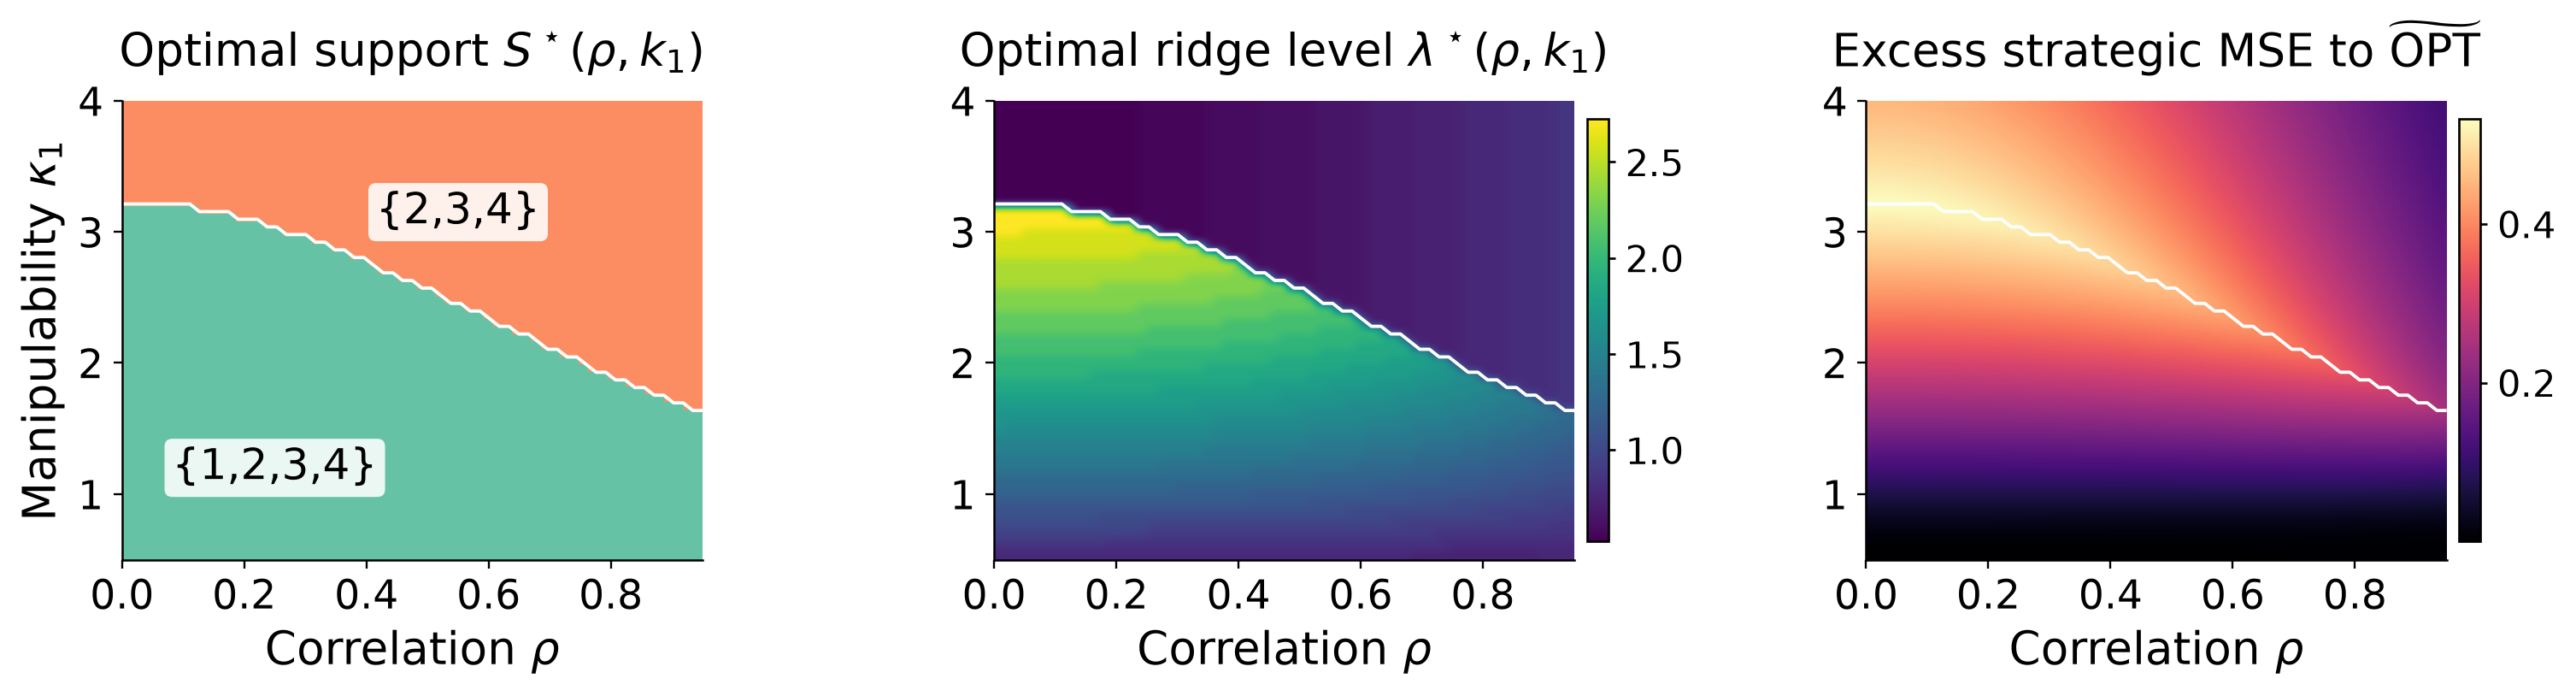

In [7]:
# Problem setup
d = 4
theta_star = np.array([1.6, 0.0, 1.0, 0.9], float)

rho_grid = np.linspace(0.0, 0.95, 61)
k1_grid = np.linspace(0.5, 4.0, 61)

lambda_grid_eval = np.concatenate(([0.0], np.geomspace(1e-4, 50.0, 240)))

support_order = [(0, 1, 2, 3), (1, 2, 3)]
support_labels = {
    (0, 1, 2, 3): '{1,2,3,4}',
    (1, 2, 3): '{2,3,4}',
}
support_colors = ['#66c2a5', '#fc8d62']

plt.rcParams.update({
    'font.size': 17.0,
    'axes.labelsize': 18.0,
    'axes.titlesize': 18.0,
    'xtick.labelsize': 16.0,
    'ytick.labelsize': 16.0,
    'legend.fontsize': 16.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 240,
    'savefig.dpi': 300,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Computations
def sigma_proxy(rho):
    return np.array([
        [1.0, rho, 0.10, 0.00],
        [rho, 1.0, 0.00, 0.10],
        [0.10, 0.00, 1.0, 0.20],
        [0.00, 0.10, 0.20, 1.0],
    ], float)

def make_k(k1):
    return np.diag([k1, 0.6, 0.5, 0.5])

def support_plain(S):
    if len(S) == 0:
        return r'$\emptyset$'
    return r'$\{' + ','.join(str(i + 1) for i in S) + r'\}$'

def support_code_string(S):
    return ''.join(str(i + 1) for i in S) if len(S) else 'empty'

def strategic_mse_batch(theta, Sigma, K):
    diff = theta - theta_star[None, :]
    pred = np.einsum('ni,ij,nj->n', diff, Sigma, diff)
    q = np.einsum('ni,ij,nj->n', theta, K, theta)
    return pred + q**2

def best_subset_ridge_grid(S, Sigma, K):
    S = tuple(S)
    if len(S) == 0:
        theta = np.zeros((1, d))
        return float(strategic_mse_batch(theta, Sigma, K)[0]), 0.0

    S_list = list(S)
    SS = Sigma[np.ix_(S_list, S_list)]
    Sy = Sigma[np.ix_(S_list, range(d))] @ theta_star
    L = len(lambda_grid_eval)
    A = SS[None, :, :] + lambda_grid_eval[:, None, None] * np.eye(len(S))[None, :, :]
    thetaS = np.linalg.solve(A, np.broadcast_to(Sy[:, None], (L, len(S), 1))).squeeze(-1)
    theta = np.zeros((L, d))
    theta[:, S_list] = thetaS
    vals = strategic_mse_batch(theta, Sigma, K)
    idx = int(np.argmin(vals))
    return float(vals[idx]), float(lambda_grid_eval[idx])

def full_zero_intercept_oracle(Sigma, K):
    rhs = Sigma @ theta_star
    q0 = float(theta_star @ K @ theta_star)

    def theta_of_q(q):
        return np.linalg.solve(Sigma + 2.0 * q * K, rhs)

    def fixed_point(q):
        th = theta_of_q(q)
        return float(th @ K @ th - q)

    hi = max(1.0, q0)
    while fixed_point(hi) > 0:
        hi *= 2.0
    q_star = brentq(fixed_point, 0.0, hi, xtol=1e-12, rtol=1e-10, maxiter=100)
    theta = theta_of_q(q_star)
    diff = theta - theta_star
    return float(diff @ Sigma @ diff + (theta @ K @ theta) ** 2)

all_supports = [S for r in range(d + 1) for S in combinations(range(d), r)]
rows = []
print("Starting computation...")
for idx_k, k1 in enumerate(k1_grid):
    K = make_k(k1)
    for rho in rho_grid:
        Sigma = sigma_proxy(rho)
        oracle_val = full_zero_intercept_oracle(Sigma, K)
        best = None
        for S in all_supports:
            val, lam = best_subset_ridge_grid(S, Sigma, K)
            if best is None or val < best['risk_star'] - 1e-12:
                best = {
                    'support': tuple(S),
                    'support_code': support_code_string(S),
                    'support_label': support_plain(S),
                    'lambda_star': lam,
                    'risk_star': val,
                }
        rows.append({
            'rho': float(rho),
            'k1': float(k1),
            'support_code': best['support_code'],
            'support_label': best['support_label'],
            'lambda_star': float(best['lambda_star']),
            'mse_subset_ridge': float(best['risk_star']),
            'tilde_opt': float(oracle_val),
            'total_gap': float(best['risk_star'] - oracle_val),
        })
    if (idx_k + 1) % 10 == 0 or idx_k == len(k1_grid) - 1:
        print(f'Completed {idx_k + 1} / {len(k1_grid)} k1 grid values')

df = pd.DataFrame(rows)
df.to_csv(OUT / 'safer_correlated_proxy_grid_colab_v260610.csv', index=False)

# Plotting setup
plt.rcParams.update({
    'font.size': 15.0,
    'axes.labelsize': 16.0,
    'axes.titlesize': 16.0,
    'xtick.labelsize': 14.0,
    'ytick.labelsize': 14.0,
    'legend.fontsize': 14.0,
})
appearing_supports = [support_code_string(S) for S in support_order if support_code_string(S) in set(df['support_code'])]
support_to_code = {s: i for i, s in enumerate(appearing_supports)}
df['support_numeric'] = df['support_code'].map(support_to_code)

rho_vals = np.sort(df['rho'].unique())
k1_vals = np.sort(df['k1'].unique())
extent = [rho_vals.min(), rho_vals.max(), k1_vals.min(), k1_vals.max()]
support_grid = df.pivot(index='k1', columns='rho', values='support_numeric').loc[k1_vals, rho_vals].values
lambda_grid = df.pivot(index='k1', columns='rho', values='lambda_star').loc[k1_vals, rho_vals].values
gap_grid = df.pivot(index='k1', columns='rho', values='total_gap').loc[k1_vals, rho_vals].values

def add_region_labels(ax):
    labels = [
        (0.25, 1.20, support_labels[(0, 1, 2, 3)]),
        (0.55, 3.15, support_labels[(1, 2, 3)]),
    ]
    for x, y, txt in labels:
        ax.text(x, y, txt, ha='center', va='center', fontsize=15.0,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.88, boxstyle='round,pad=0.18'))

def add_boundary(ax, lw=1.15):
    if len(appearing_supports) > 1:
        ax.contour(rho_vals, k1_vals, support_grid,
                   levels=np.arange(0.5, len(appearing_supports) - 0.49, 1.0),
                   colors='white', linewidths=lw)

def prettify(ax):
    ax.tick_params(length=3.0, width=0.7)
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)

fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.55), constrained_layout=False)
fig.subplots_adjust(left=0.055, right=0.985, top=0.85, bottom=0.22, wspace=0.25)

cmap_support = ListedColormap(support_colors[:len(appearing_supports)])
norm_support = BoundaryNorm(np.arange(-0.5, len(appearing_supports) + 0.5, 1.0), cmap_support.N)

# Left panel: optimal support
ax = axes[0]
im1 = ax.imshow(support_grid, origin='lower', aspect='auto', extent=extent,
          cmap=cmap_support, norm=norm_support, interpolation='nearest')
add_boundary(ax)
add_region_labels(ax)
ax.set_title(r'Optimal support $S^\star(\rho,k_1)$', loc='center', pad=12)
ax.set_xlabel(r'Correlation $\rho$')
ax.set_ylabel(r'Manipulability $\kappa_1$')
ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8])
ax.set_yticks([1.0, 2.0, 3.0, 4.0])
cbar1 = fig.colorbar(im1, ax=ax, shrink=0.92, pad=0.018)
cbar1.ax.set_visible(False)
prettify(ax)

# Mid panel: optimal ridge level
ax = axes[1]
im2 = ax.imshow(lambda_grid, origin='lower', aspect='auto', extent=extent,
                cmap='viridis', interpolation='bicubic')
add_boundary(ax)
ax.set_title(r'Optimal ridge level $\lambda^\star(\rho,k_1)$', loc='center', pad=12)
ax.set_xlabel(r'Correlation $\rho$')
ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8])
ax.set_yticks([1.0, 2.0, 3.0, 4.0])
cbar2 = fig.colorbar(im2, ax=ax, shrink=0.92, pad=0.018)
cbar2.ax.tick_params(labelsize=13.0, length=2.5)
prettify(ax)

# Right panel: excess strategic MSE
ax = axes[2]
im3 = ax.imshow(gap_grid, origin='lower', aspect='auto', extent=extent,
                cmap='magma', interpolation='bicubic')
add_boundary(ax)
ax.set_title(r'Excess strategic MSE to $\widetilde{\mathrm{OPT}}$', loc='center', pad=12)
ax.set_xlabel(r'Correlation $\rho$')
ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8])
ax.set_yticks([1.0, 2.0, 3.0, 4.0])
cbar3 = fig.colorbar(im3, ax=ax, shrink=0.92, pad=0.018)
cbar3.ax.tick_params(labelsize=13.0, length=2.5)
prettify(ax)

fig.savefig(os.path.join(plots_dir, 'safer_correlated_proxy.pdf'), bbox_inches='tight')
fig.savefig(os.path.join(plots_dir, 'safer_correlated_proxy.png'), bbox_inches='tight', dpi=300)

plt.show()